In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import pandas as pd
import numpy as np

# Set seed for reproducibility
np.random.seed(42)
n_rows = 5000

# 1. Define Categories (Same column names)
crops = [
    'rice', 'maize', 'ragi', 'horse gram', 'moth bean', 'peas/beans', 
    'safflower', 'potato', 'tomato', 'brinjal', 'cucurbits', 
    'cabbage', 'cauliflower', 'bhindi', 'onion'
]
soils = ['sandy clay loam', 'clay', 'sandy loam', 'loam', 'loamy sand', 'clay loam']

# Purulia context: Kharif is dominant, Rabi is limited, Zaid is almost non-existent/risky
seasons = ['Kharif', 'Rabi', 'Zaid']
season_probs = [0.70, 0.25, 0.05] # 70% of data is Kharif, only 5% is Zaid

# 2. Base Prices (₹/Tonne) and Yields (Tonnes/Hectare)
base_prices = {
    'rice': 22000, 'maize': 21000, 'ragi': 35000, 'horse gram': 60000, 
    'moth bean': 55000, 'peas/beans': 45000, 'safflower': 55000, 
    'potato': 15000, 'tomato': 20000, 'brinjal': 18000, 'cucurbits': 16000, 
    'cabbage': 12000, 'cauliflower': 15000, 'bhindi': 25000, 'onion': 18000
}
base_yields = {
    'rice': 4.0, 'maize': 3.5, 'ragi': 2.0, 'horse gram': 1.0, 
    'moth bean': 0.8, 'peas/beans': 1.5, 'safflower': 1.2, 
    'potato': 25.0, 'tomato': 30.0, 'brinjal': 20.0, 'cucurbits': 15.0, 
    'cabbage': 30.0, 'cauliflower': 25.0, 'bhindi': 12.0, 'onion': 20.0
}

# 3. Generate Base Data
df = pd.DataFrame({
    'crop': np.random.choice(crops, n_rows),
    'soil_type': np.random.choice(soils, n_rows),
    'season': np.random.choice(seasons, n_rows, p=season_probs),
    # Purulia rainfall is heavily monsoon-dependent
    'rainfall_mm': np.random.normal(1100, 300, n_rows).clip(100, 2000),
    'temperature_c': np.random.normal(27, 7, n_rows).clip(10, 45),
    'humidity_pct': np.random.normal(65, 15, n_rows).clip(20, 95),
    'soil_ph': np.random.normal(6.5, 0.8, n_rows).clip(4.5, 8.5),
    'nitrogen_kg_ha': np.random.normal(180, 40, n_rows).clip(50, 350),
    'phosphorus_kg_ha': np.random.normal(30, 10, n_rows).clip(10, 80),
    'potassium_kg_ha': np.random.normal(130, 30, n_rows).clip(50, 250)
})

# 4. Simulate Yield (Purulia Reality)
soil_factors = {'sandy clay loam': 0.9, 'clay': 0.8, 'sandy loam': 0.85, 'loam': 1.1, 'loamy sand': 0.7, 'clay loam': 1.0}
df['soil_multiplier'] = df['soil_type'].map(soil_factors)

# Yield is heavily dependent on monsoon rain (ideal ~1100mm)
rain_factor = 1 - (abs(df['rainfall_mm'] - 1100) / 2000)
temp_factor = 1 - (abs(df['temperature_c'] - 27) / 40)
weather_multiplier = (rain_factor + temp_factor) / 2

# Severe penalty if water is critically low (drought)
drought_mask = (df['rainfall_mm'] < 400)
weather_multiplier.loc[drought_mask] = weather_multiplier.loc[drought_mask] * 0.3 # Massive yield drop

nutrient_multiplier = ((df['nitrogen_kg_ha'] / 180) + (df['phosphorus_kg_ha'] / 30) + (df['potassium_kg_ha'] / 130)) / 3

df['actual_yield_t_ha'] = df['crop'].map(base_yields) * df['soil_multiplier'] * weather_multiplier * nutrient_multiplier
df['actual_yield_t_ha'] = df['actual_yield_t_ha'] + np.random.normal(0, 0.3, n_rows)
df['actual_yield_t_ha'] = df['actual_yield_t_ha'].clip(lower=0.0) # Crop can be 0 if completely destroyed

# 5. Simulate Market Prices with Seasonality
season_price_multiplier = {'Kharif': 1.0, 'Rabi': 1.15, 'Zaid': 1.25}
df['market_price'] = df['crop'].map(base_prices) * df['season'].map(season_price_multiplier)

# Zaid in Purulia is highly risky (if it's Zaid AND no rain, prices crash because quality is bad, and yield is gone)
zaid_drought_mask = (df['season'] == 'Zaid') & (df['rainfall_mm'] < 400)
df.loc[zaid_drought_mask, 'market_price'] *= 0.80 

df['revenue_inr'] = df['actual_yield_t_ha'] * df['market_price'] * np.random.normal(1.0, 0.05, n_rows)

# 6. Cost of Production
fixed_cost = 15000 
fertilizer_cost = (df['nitrogen_kg_ha'] * 6) + (df['phosphorus_kg_ha'] * 25) + (df['potassium_kg_ha'] * 15)
harvesting_cost = df['actual_yield_t_ha'] * 2000
df['cost_inr'] = fixed_cost + fertilizer_cost + harvesting_cost + np.random.normal(0, 2000, n_rows)

# 7. Final Target: Absolute Profit in INR
df['profit_inr'] = df['revenue_inr'] - df['cost_inr']



In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   crop               5000 non-null   str    
 1   soil_type          5000 non-null   str    
 2   season             5000 non-null   str    
 3   rainfall_mm        5000 non-null   float64
 4   temperature_c      5000 non-null   float64
 5   humidity_pct       5000 non-null   float64
 6   soil_ph            5000 non-null   float64
 7   nitrogen_kg_ha     5000 non-null   float64
 8   phosphorus_kg_ha   5000 non-null   float64
 9   potassium_kg_ha    5000 non-null   float64
 10  soil_multiplier    5000 non-null   float64
 11  actual_yield_t_ha  5000 non-null   float64
 12  market_price       5000 non-null   float64
 13  revenue_inr        5000 non-null   float64
 14  cost_inr           5000 non-null   float64
 15  profit_inr         5000 non-null   float64
dtypes: float64(13), str(3)
memory usage

In [5]:
df["ROI_pct"] = (df["profit_inr"]/df["cost_inr"]) * 100 #Return on Investment

In [6]:
df.sample(20)

,crop,soil_type,season,rainfall_mm,temperature_c,humidity_pct,soil_ph,nitrogen_kg_ha,phosphorus_kg_ha,potassium_kg_ha,soil_multiplier,actual_yield_t_ha,market_price,revenue_inr,cost_inr,profit_inr,ROI_pct
2563,peas/beans,sandy loam,Kharif,1242.469197,33.238018,85.489028,5.920645,219.304786,35.265937,120.491746,0.85,1.283681,45000.0,60121.473383,23704.035798,36417.437584,153.633912
1654,tomato,clay loam,Rabi,824.816675,18.043714,48.413271,6.289179,176.701170,38.816442,177.993047,1.00,29.459359,23000.0,752149.931945,78720.142038,673429.789907,855.473291
2178,onion,clay loam,Rabi,806.271974,35.380041,91.775238,6.099911,114.469575,24.144428,150.865156,1.00,14.362998,20700.0,292201.551793,46044.470223,246157.081570,534.607262
3052,safflower,sandy clay loam,Rabi,1089.750011,29.679041,65.084132,4.500000,196.648932,42.768143,77.189159,0.90,0.895767,63250.0,57260.332775,20569.217944,36691.114831,178.378755
3253,ragi,clay loam,Kharif,1610.537630,25.858658,73.795729,5.823571,205.754054,22.354402,87.366995,1.00,1.149251,35000.0,40877.177561,21291.674696,19585.502865,91.986672
3650,cabbage,sandy clay loam,Rabi,1207.808049,19.464278,61.828367,5.735001,157.557968,34.073558,84.283353,0.90,20.845668,13800.0,306828.241652,59531.843362,247296.398291,415.401883
4127,rice,sandy clay loam,Kharif,1355.266169,20.072005,74.631306,5.791306,165.278733,19.531533,158.795378,0.90,2.317777,22000.0,52104.593427,25057.933863,27046.659564,107.936511
3227,ragi,sandy loam,Kharif,1293.933167,27.795099,48.299205,6.601602,173.368188,39.743032,114.705701,0.85,1.720650,35000.0,61936.865903,22248.363420,39688.502483,178.388413
4354,ragi,clay loam,Kharif,1054.911422,32.292364,41.626189,6.894829,227.947069,29.575317,122.116160,1.00,1.574162,35000.0,53802.192087,23283.484739,30518.707349,131.074483
2583,maize,loam,Kharif,1264.109333,23.506940,77.598453,6.594097,190.583375,25.641144,113.014918,1.10,3.036059,21000.0,61535.751337,25684.252029,35851.499308,139.585530


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   crop               5000 non-null   str    
 1   soil_type          5000 non-null   str    
 2   season             5000 non-null   str    
 3   rainfall_mm        5000 non-null   float64
 4   temperature_c      5000 non-null   float64
 5   humidity_pct       5000 non-null   float64
 6   soil_ph            5000 non-null   float64
 7   nitrogen_kg_ha     5000 non-null   float64
 8   phosphorus_kg_ha   5000 non-null   float64
 9   potassium_kg_ha    5000 non-null   float64
 10  soil_multiplier    5000 non-null   float64
 11  actual_yield_t_ha  5000 non-null   float64
 12  market_price       5000 non-null   float64
 13  revenue_inr        5000 non-null   float64
 14  cost_inr           5000 non-null   float64
 15  profit_inr         5000 non-null   float64
 16  ROI_pct            5000 non-null   

In [8]:



# 3. Water Availability (Rain + Humidity)
df['water_availability'] = df['rainfall_mm'] * (df['humidity_pct'] / 100)

# 4. Heat Stress Index (High temp + High humidity = bad for some crops)
df['heat_stress'] = df['temperature_c'] * df['humidity_pct']

# 5. DROP THE LEAKY COLUMNS
# We DROP Yield, Revenue, Cost, and Market Price.
# The model must predict the margin ONLY using the environment and crop type!
cols_to_drop = ['actual_yield_t_ha', 'revenue_inr', 'cost_inr', 'market_price', 'soil_multiplier',"profit_inr"]
df_clean = df.drop(columns=cols_to_drop)

# Display the final columns

print(df_clean.columns.tolist())

['crop', 'soil_type', 'season', 'rainfall_mm', 'temperature_c', 'humidity_pct', 'soil_ph', 'nitrogen_kg_ha', 'phosphorus_kg_ha', 'potassium_kg_ha', 'ROI_pct', 'water_availability', 'heat_stress']


In [9]:
corr_matrix = df_clean.select_dtypes(include=[np.number]).corr()

In [10]:
target_corr = corr_matrix.abs()["ROI_pct"]
redundent_cols = target_corr[target_corr<0.1].index.to_list()
redundent_cols

['rainfall_mm',
 'temperature_c',
 'humidity_pct',
 'soil_ph',
 'nitrogen_kg_ha',
 'potassium_kg_ha',
 'water_availability',
 'heat_stress']

In [11]:
imp_col_list = ["rainfall_mm","temperature_c","soil_ph"]
for item in imp_col_list:
    redundent_cols.remove(item)

In [12]:
df1 = df_clean.drop(columns=redundent_cols, errors="raise").copy()
df1.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   crop              5000 non-null   str    
 1   soil_type         5000 non-null   str    
 2   season            5000 non-null   str    
 3   rainfall_mm       5000 non-null   float64
 4   temperature_c     5000 non-null   float64
 5   soil_ph           5000 non-null   float64
 6   phosphorus_kg_ha  5000 non-null   float64
 7   ROI_pct           5000 non-null   float64
dtypes: float64(5), str(3)
memory usage: 312.6 KB


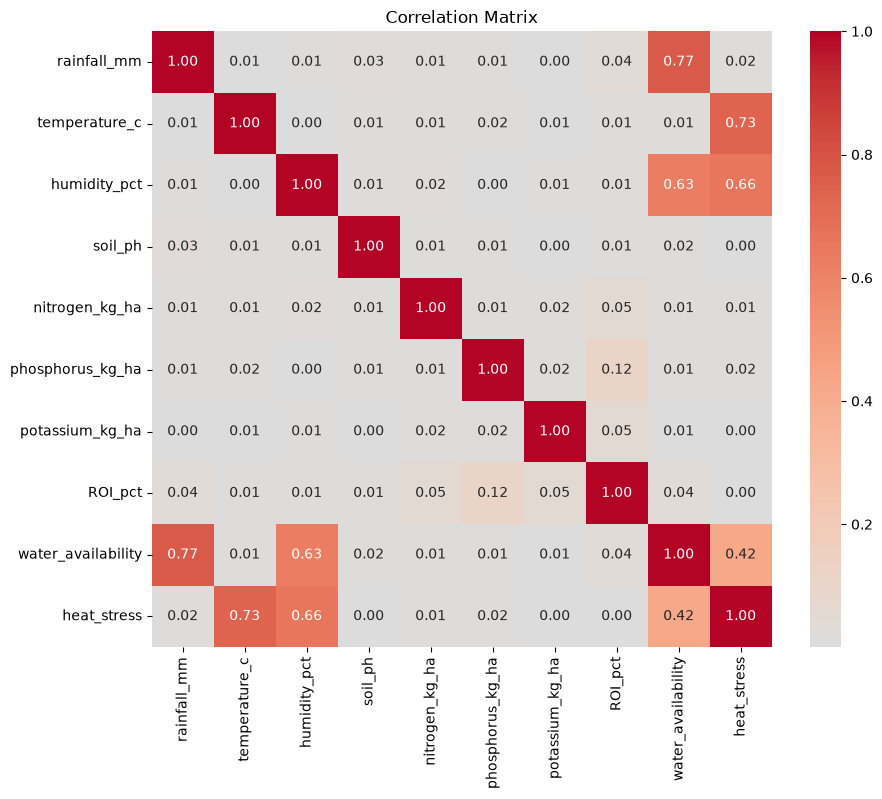

In [13]:
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix.abs(),annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Correlation Matrix")
plt.show()

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# 1. Select numeric features and drop NaN values
x_features = df1.select_dtypes(include=[np.number]).dropna()

# 2. Calculate VIF for each column
vif_data = pd.DataFrame()
vif_data["Feature"] = x_features.columns
vif_data["VIF"] = [variance_inflation_factor(x_features.values, i) for i in range(x_features.shape[1])]

# 3. Filter columns with high VIF (> 10)
high_vif_cols = vif_data[vif_data["VIF"] > 10]["Feature"].tolist()

print(vif_data.sort_values(by="VIF", ascending=False))
print("\nHigh VIF Columns:", high_vif_cols)

            Feature       VIF
4           ROI_pct  1.015800
3  phosphorus_kg_ha  1.014595
0       rainfall_mm  1.002451
2           soil_ph  1.001006
1     temperature_c  1.000734

High VIF Columns: []


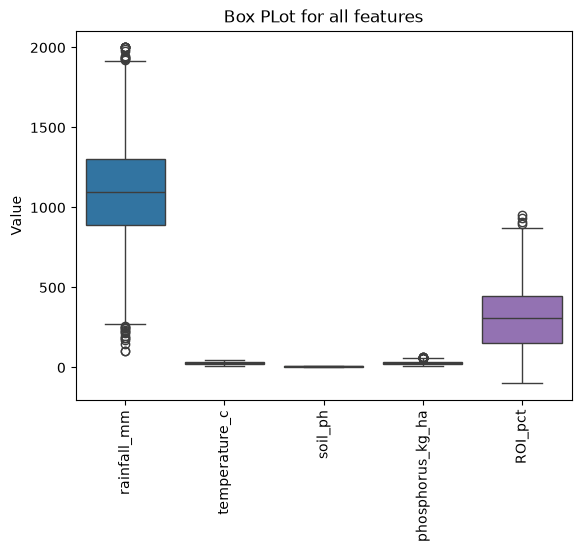

In [15]:
df_box = df1.select_dtypes(include=[np.number])
sns.boxplot(data=df_box)
plt.title("Box PLot for all features")
plt.ylabel("Value")
plt.xticks(rotation=90)
plt.show()

In [16]:

target_col = "ROI_pct"
feature_cols = [
        c for c in df1.select_dtypes(include="number").columns
        if c != target_col
]

Q1 = df1[feature_cols].quantile(0.25)
Q3 = df1[feature_cols].quantile(0.75)
IQR = Q3 - Q1

mask = (
        (df1[feature_cols] < (Q1 - 1.5 * IQR)) |
        (df1[feature_cols] > (Q3 + 1.5 * IQR))
).any(axis=1)

df1 = df1.loc[~mask].copy()

df1 = df1.loc[~mask].copy()


In [17]:
from sklearn.model_selection import train_test_split

X = df1.drop(columns=[target_col])
y = df1[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (3958, 7) (3958,)
Test set: (990, 7) (990,)


In [18]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.to_list()
cat_cols = ["soil_texture","season","crop"]
num_cols

['rainfall_mm', 'temperature_c', 'soil_ph', 'phosphorus_kg_ha']

In [19]:
print(y.dtype)          # float64? int64? object?
print(y.nunique())      # how many unique values?
print(y.head())

float64
4941
0     32.982621
1    233.171548
2    297.367946
3    486.861857
4    327.054403
Name: ROI_pct, dtype: float64


In [20]:
# Does any single feature correlate ~perfectly with y?
corr = X.select_dtypes('number').corrwith(y).abs().sort_values(ascending=False)
print(corr.head(10))

phosphorus_kg_ha    0.111851
rainfall_mm         0.034557
soil_ph             0.011050
temperature_c       0.010753
dtype: float64


In [21]:
X_train.columns

Index(['crop', 'soil_type', 'season', 'rainfall_mm', 'temperature_c',
       'soil_ph', 'phosphorus_kg_ha'],
      dtype='str')

                            OLS Regression Results                            
Dep. Variable:                ROI_pct   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     12.77
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           2.51e-10
Time:                        18:56:52   Log-Likelihood:                -26328.
No. Observations:                3958   AIC:                         5.267e+04
Df Residuals:                    3953   BIC:                         5.270e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              260.5220     30.597  

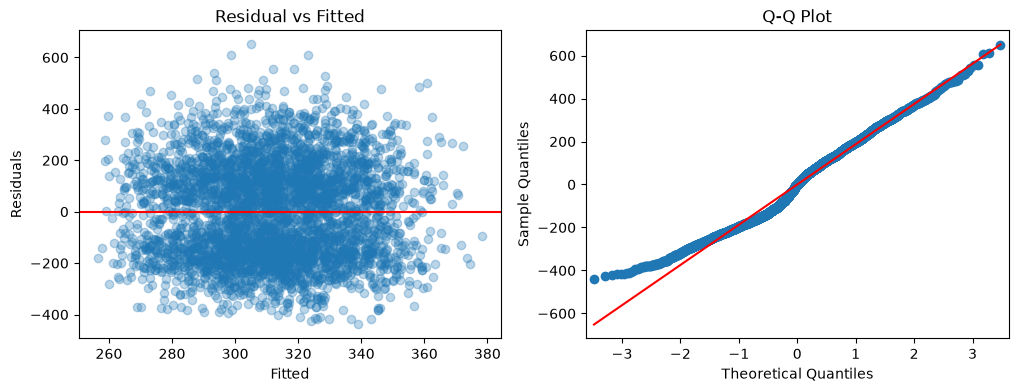

In [22]:

import statsmodels.api as sm

X_const = sm.add_constant(X_train[num_cols].fillna(0))
model = sm.OLS(y_train, X_const).fit()
print(model.summary())          # coefficients, R², F-stat, p-values

# Residual plots
resid = model.resid
fitted = model.fittedvalues

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(fitted, resid, alpha=0.3); ax[0].axhline(0, color='r')
ax[0].set_xlabel('Fitted'); ax[0].set_ylabel('Residuals'); ax[0].set_title('Residual vs Fitted')

sm.qqplot(resid, line='s', ax=ax[1]); ax[1].set_title('Q-Q Plot')
plt.show()

In [23]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor

# 1. Drop the leaky column (if you haven't already)
if 'cost_of_production' in X.columns:
    X = X.drop(columns=['cost_of_production'])
    print("Dropped 'cost_of_production' from features.")

# 2. AUTOMATICALLY find the new lists of columns
# This guarantees you won't get a KeyError
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Safety check: Ensure target isn't accidentally in X
if 'profit_margin_pct' in num_cols:
    num_cols.remove('profit_margin_pct')

print(f"Number of numeric features: {len(num_cols)}")
print(f"Number of categorical features: {len(cat_cols)}")

# 3. Rebuild the Preprocessor with the safe lists
pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore',sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols)
])

# 4. Re-run the Bake-Off (Same as before)
models = {
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=42)
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []
best_score = -np.inf
best_pipe = None

print("\nEvaluating Tree Models without leakage...\n")

for name, model in models.items():
    pipe = Pipeline([
        ('pre', pre),
        ('reg', model)
    ])
    
    cv_scores = cross_validate(
        pipe, X_train, y_train, cv=cv, 
        scoring=['r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_error'],
        n_jobs=-1
    )
    
    r2 = cv_scores['test_r2'].mean()
    rmse = -cv_scores['test_neg_root_mean_squared_error'].mean()
    mae = -cv_scores['test_neg_mean_absolute_error'].mean()
    
    results.append({'Model': name, 'R² Score': r2, 'RMSE': rmse, 'MAE': mae})
    
    if r2 > best_score:
        best_score = r2
        best_pipe = pipe
        best_model_name = name

print(pd.DataFrame(results).sort_values(by='R² Score', ascending=False).to_string(index=False))
print(f"\n🏆 Winner: {best_model_name} with R² = {best_score:.4f}")

# Fit the best model so we can use it for "What-If" scenarios
best_pipe.fit(X_train, y_train)

C:\Users\praty\AppData\Local\Temp\ipykernel_10288\3024827520.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


Number of numeric features: 4
Number of categorical features: 3

Evaluating Tree Models without leakage...

                 Model  R² Score      RMSE       MAE
Hist Gradient Boosting  0.900458 59.329966 44.392589
         Random Forest  0.887269 63.069669 47.441004
           Extra Trees  0.880448 65.013356 48.586934
         Decision Tree  0.793682 85.378591 64.794454

🏆 Winner: Hist Gradient Boosting with R² = 0.9005


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['crop','soil_type','season',...,'temperature_c','soil_ph', 'phosphorus_kg_ha']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis co

In [24]:
df1.sample(10)

,crop,soil_type,season,rainfall_mm,temperature_c,soil_ph,phosphorus_kg_ha,ROI_pct
1448,potato,loamy sand,Rabi,618.387167,25.800054,6.021116,44.968181,421.568280
2241,rice,loamy sand,Zaid,1147.242439,28.534532,5.832035,15.612379,160.893163
134,potato,clay,Kharif,1152.435448,29.920162,5.441377,12.865477,411.554442
4897,safflower,sandy loam,Kharif,1452.598503,34.553068,6.403961,44.773502,77.853611
3755,cabbage,sandy loam,Kharif,1331.924712,18.314681,5.806125,33.475130,307.343110
153,cabbage,loamy sand,Rabi,625.908308,25.558394,5.685231,29.318394,412.497277
1114,maize,loam,Zaid,736.837240,16.167655,6.349931,37.047604,249.262027
2909,rice,loam,Kharif,1240.782471,20.710672,7.288095,43.169544,230.553582
515,cabbage,sandy clay loam,Kharif,593.049193,31.351549,7.031595,23.866458,327.128563
4770,onion,loam,Kharif,758.311285,20.453019,8.500000,19.636591,372.879573


In [25]:
import pandas as pd

# Use a baseline row
baseline = X_test.iloc[[0]].copy()
crops_to_test = ['potato', 'cabbage', 'maize', 'rice']

# 1. NORMAL SCENARIO
normal = pd.concat([baseline] * len(crops_to_test), ignore_index=True)
normal['crop'] = crops_to_test
normal['predicted_ROI_pct'] = pipe.predict(normal)

# 2. DROUGHT SCENARIO
drought = pd.concat([baseline] * len(crops_to_test), ignore_index=True)
drought['crop'] = crops_to_test
drought['rainfall_mm'] = 300       # Low rain
drought['temperature_c'] = 38      # High heat
drought['predicted_ROI_pct'] = pipe.predict(drought)

print("--- NORMAL CONDITIONS (Profit in ₹) ---")
print(normal[['crop', 'predicted_ROI_pct']].sort_values('predicted_ROI_pct', ascending=False).to_string(index=False))

print("\n--- DROUGHT CONDITIONS (Profit in ₹) ---")
print(drought[['crop', 'predicted_ROI_pct']].sort_values('predicted_ROI_pct', ascending=False).to_string(index=False))

--- NORMAL CONDITIONS (Profit in ₹) ---
   crop  predicted_ROI_pct
 potato         450.210337
cabbage         364.353033
   rice         253.246437
  maize         184.334736

--- DROUGHT CONDITIONS (Profit in ₹) ---
   crop  predicted_ROI_pct
 potato         214.446462
cabbage         153.489633
   rice          60.196410
  maize          13.357188


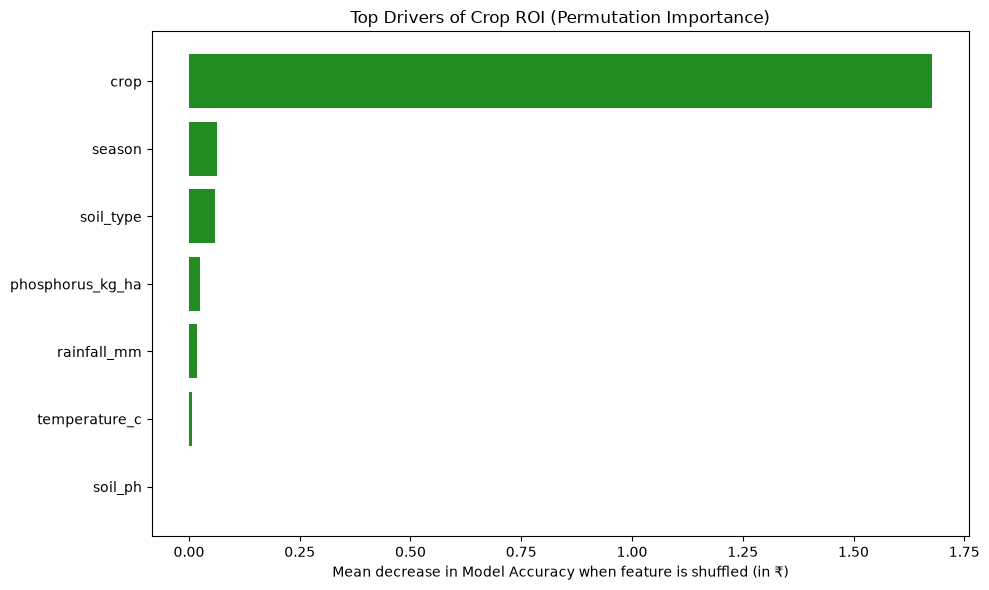

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# 1. Calculate Permutation Importance on the Test Set
result = permutation_importance(
    best_pipe, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

# 2. Use the ORIGINAL column names from X_test (NOT the one-hot encoded names)
original_names = X_test.columns

# 3. Create the DataFrame
importance_df = pd.DataFrame({
    'Feature': original_names,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# 4. Plot
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'][:15][::-1], importance_df['Importance'][:15][::-1], color='forestgreen')
plt.xlabel('Mean decrease in Model Accuracy when feature is shuffled (in ₹)')
plt.title('Top Drivers of Crop ROI (Permutation Importance)')
plt.tight_layout()
plt.show()

In [27]:
import joblib
joblib.dump(best_pipe, 'crop_profit_model(ROI).pkl')

['crop_profit_model(ROI).pkl']

In [28]:


# Save the entire pipeline (Preprocessing + Model)
joblib.dump(best_pipe, 'crop_profit_model(ROI).joblib')

print("Model saved successfully!")

Model saved successfully!


In [29]:
import json

# Save the exact column names the model was trained on
columns_list = X_train.columns.tolist()
with open('model_columns.json', 'w') as f:
    json.dump(columns_list, f)
# Check if new data has all columns
# new_farm_scenario = new_farm_scenario[expected_columns] # Reorder to match

In [30]:
import json

with open('model_columns.json', 'r') as f:
    expected_columns = json.load(f)

# Check if new data has all columns
# new_farm_scenario = new_farm_scenario[expected_columns] # Reorder to match